In [1]:
#Download the datafile we will use.
!wget https://exomol.com/db/CaOH/40Ca-16O-1H/OYT6/40Ca-16O-1H__OYT6.states.bz2

--2026-11-24 14:05:34--  https://exomol.com/db/CaOH/40Ca-16O-1H/OYT6/40Ca-16O-1H__OYT6.states.bz2
Resolving exomol.com (exomol.com)... 128.40.3.60
Connecting to exomol.com (exomol.com)|128.40.3.60|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 54899736 (52M) [application/x-bzip2]
Saving to: ‘40Ca-16O-1H__OYT6.states.bz2.1’

40Ca-16O-1H__OYT6.s 100%[===================>]  52.36M  11.9MB/s    in 5.3s    

2026-11-24 14:05:41 (9.97 MB/s) - ‘40Ca-16O-1H__OYT6.states.bz2.1’ saved [54899736/54899736]



In this exercise, we will try to use different regression model to predict the energy levels of CaOH. In the first cell, we have downloaded the CaOH state file, that contains the energy level of the molecule for its first three electronic states. More information on the system can be found in the [original paper](https://doi.org/10.1093/mnras/stac2462).


The  states file is in the following format( see the [most recent ExoMol paper](https://doi.org/10.48550/arXiv.2406.06347) for the formatting of more recent data)
| Field                  | Description                                                                 |
|------------------------|-----------------------------------------------------------------------------|
| index                  | State ID                                                                    |
| Energy                 | Recommended state energy in $\mathrm{cm^{-1}}$                              |
| $g$                    | State degeneracy                                                            |
| $J$                    | Total angular momentum quantum number, $J$ or $F$ (integer/half-integer)    |
| Unc                    | Uncertainty in the state energy in $\mathrm{cm^{-1}}$                       |
|$τ$ | Lifetime (s)|
|+/-                     | Total parity (QN) |
|e/f                     | Rotationless-parity  (QN) |
|N                       | Rotational angular momentum (QN) |
|Label                   | Electronic state |
|L                       | Vibronic angular momentum quantum number
|v1                      | Symmetric stretching v1 mode vibrational quantum number
|v2                      | Bending v2 mode vibrational quantum number
|l2                      | Vibrational angular momentum quantum number associated with v2 mode
|v3                      | Antisymmetric stretching v3 mode vibrational quantum number
|Omega                   | Projection of the total angular momentum
|fidx                    | Spin components F1 and F3
|E2                      | Original computed calculated state energy
|orig                    | Label 'Ma' for experimentals, 'Ca' for calculated


__Instructions__

Complete and run the cells. Each session has a few questions that need to be answered. Write your answers inside the Notebook. Please send to my address (marc.pezzman@gmail.com) the PDF and the compiled Notebook file.

In [2]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score, mean_absolute_error
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.svm import SVC, LinearSVR
from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import Ridge, Lasso
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import time


In [3]:

# Create the object and name the files.
names=["index","Energy","g","J","unc","tau","parity","e/f","N","label","L","v1","v2","l2","v3","omega","fidx","E2","orig"]
data = pd.read_csv('40Ca-16O-1H__OYT6.states.bz2', sep=r"\s+",header=None, names=names)

#  Move labels from characters to numeric
data['label_num'] = data['label'].map({'X(2SIGMA+)':0, "A'(2PI)":1, 'A"(2PI)':2})
data['fidx_num'] = data['fidx'].map({'F1':1, "F2":2, 'F3':3})
data['parity_num'] = data['parity'].map({'+':1, '-':0})

# Quick look at the data
print("Data sample:")
print(data.head())



Data sample:
   index      Energy  g    J        unc           tau parity e/f  N  \
0      1    0.667513  4  0.5   0.000058  2.094000e+07      -   f  1   
1      2  353.300012  4  0.5  10.000000  1.026400e+00      -   f  1   
2      3  609.705471  4  0.5  10.000000  2.378600e-01      -   f  1   
3      4  689.349393  4  0.5  10.000000  1.441500e+00      -   f  1   
4      5  951.015829  4  0.5  10.000000  4.036500e-01      -   f  1   

        label  ...  v2  l2  v3  omega  fidx          E2 orig  label_num  \
0  X(2SIGMA+)  ...   0   0   0    0.5    F2    0.668704   Ma          0   
1  X(2SIGMA+)  ...   1   1   0    0.5    F2  353.300012   Ca          0   
2  X(2SIGMA+)  ...   0   0   0    0.5    F2  609.705471   Ca          0   
3  X(2SIGMA+)  ...   2   0   0    0.5    F2  689.349393   Ca          0   
4  X(2SIGMA+)  ...   1   1   0    0.5    F2  951.015829   Ca          0   

  fidx_num  parity_num  
0        2           0  
1        2           0  
2        2           0  
3        

In [4]:
# Get an idea of the database size
len(data["J"])

3187522

In [5]:
features = ["J","L","v1","v2","l2","v3","omega","fidx_num","label_num"]

X = data[features]

y_class = data["orig"]      # for classification
y_reg = data["Energy"]      # for regression


__Exercise 1: Classification__

As you can see, the last label identifies the origin of the energy level, if it is calculated from experimental label it is identifies as "Ma", if it is obtained by calculations is identified as "Ca".

We will try to predict them with the features defined above.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2)


Complete the following snippets in order to introduce the appropriate classifier required and plot the features importance for each of them. Some of the tasks will require some time, don't worry.

Classification Accuracy: 0.9998839224790393


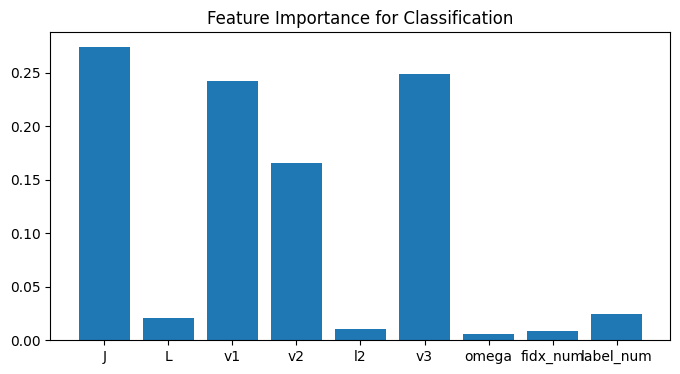

In [7]:
#Random Forest
clf = RandomForestClassifier(n_estimators=20)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Classification Accuracy:", accuracy_score(y_test, y_pred))

# Feature importance plot
importances = clf.feature_importances_
plt.figure(figsize=(8,4))
plt.bar(features, importances)
plt.title("Feature Importance for Classification")
plt.show()


Classification Accuracy: 0.9996674535885993


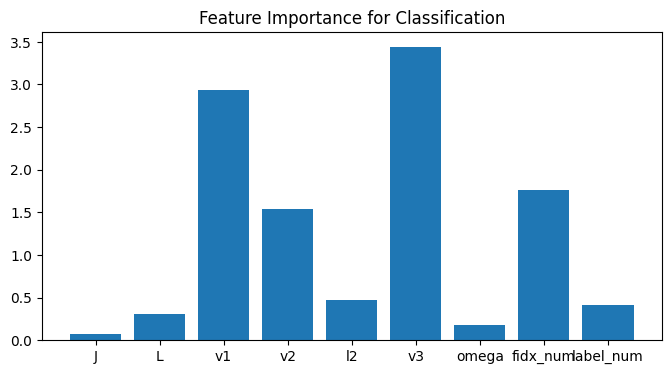

In [8]:
# Logistic Regression
clf = LogisticRegression(max_iter=500)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print("Classification Accuracy:", accuracy_score(y_test, y_pred))
importances = abs(clf.coef_[0])   # coef_ is a 2D array: [class, feature]
plt.figure(figsize=(8,4))
plt.bar(features, importances)
plt.title("Feature Importance for Classification")
plt.show()



The supporting vector methodology is a bit heavier, for this reason we will work with a small subset of the database (we will consider values of $J \leq 10$).

In [9]:
data_small=data[data["J"] < 11]

X_small = data_small[features]

y_class_small = data_small["orig"]        # for classification
y_reg_small   = data_small["Energy"]      # for regression
X_train_small, X_test_small, y_train_small, y_test_small = train_test_split(X_small, y_class_small, test_size=0.2)

print(len(data_small["J"]))

120796


Classification Accuracy: 0.997682119205298


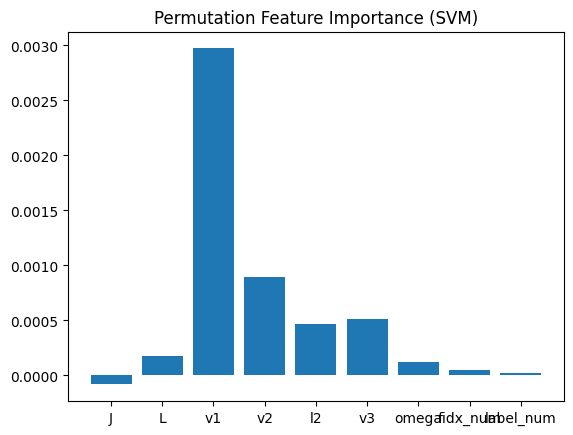

In [10]:
clf = SVC(kernel='rbf', probability=True)
clf.fit(X_train_small, y_train_small)

y_pred = clf.predict(X_test_small)
print("Classification Accuracy:", accuracy_score(y_test_small, y_pred))

result = permutation_importance(clf, X_test_small, y_test_small, n_repeats=5)
importances = result.importances_mean

plt.bar(features, importances)
plt.title("Permutation Feature Importance (SVM)")
plt.show()


Classification Accuracy: 0.9983029801324503


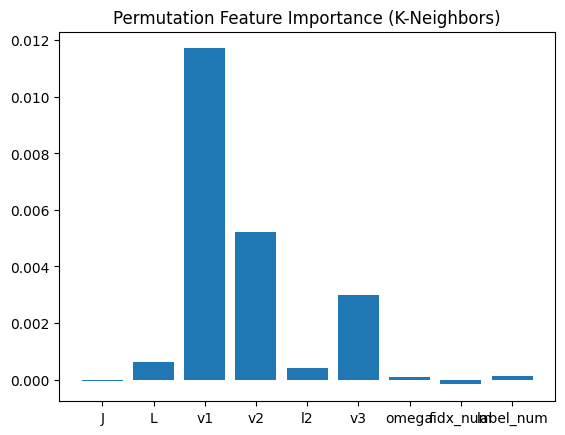

In [11]:
# K-Neighbors Classifier
clf = KNeighborsClassifier(n_neighbors=2)
clf.fit(X_train_small, y_train_small)

y_pred = clf.predict(X_test_small)
print("Classification Accuracy:", accuracy_score(y_test_small, y_pred))

result = permutation_importance(clf, X_test_small, y_test_small, n_repeats=5)
importances = result.importances_mean

plt.bar(features, importances)
plt.title("Permutation Feature Importance (K-Neighbors)")
plt.show()

__Questions__
1. Do you see any particular change in accuracy within the models used in assessing the origin of the energy levels?
2. Which features are shared between the Random Forest Classifier and the Logistic Regression?
3. Which features are shared between the Supporting Vector Classifier and the K-Neighbors Regression?
4. Is it possible to make a comparison between results obtained using a large datasets and the ones using a small one? Why?

__Exercise 2: Regression__

We will play now a bit with some regression models for predicting the energies Play a bit with the parameters to try to optimise the RMSE and R$^2$ results! Please keep in mind that, due to the large amount of data and the complexity of the task, we do expect RMSE quite high, between 400 and 2000 cm$^{-1}$.

You will have a bonus in your evaluation if you will be able to get results with RMSE below the ones I got.

__IMPORTANT:__ Remember to specifiy "random_state" to make your results reproducible.


In [12]:
# Define train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2)

Mean Squared Error (MSE): 13709857.1558
Root Mean Squared Error (RMSE): 3702.6824
R² Score: 0.8173


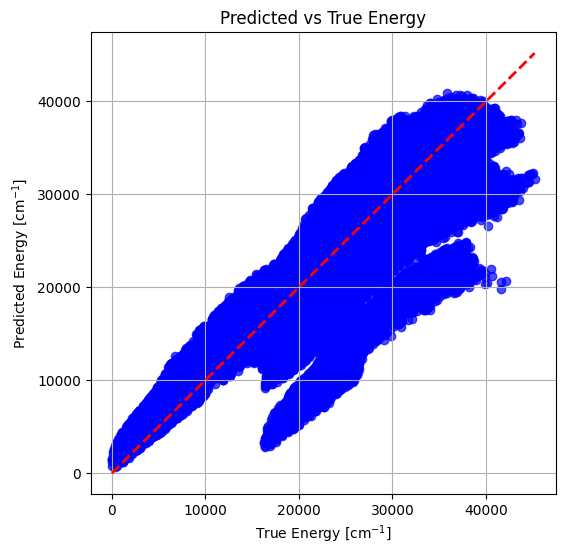

In [13]:
#Linear Regression
reg = LinearRegression()
reg.fit(X_train, y_train)
y_pred = reg.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.4f}")
print(f"R² Score: {r2:.4f}")

# Plot Predicted vs True energies
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel(r"True Energy [cm$^{-1}$]")
plt.ylabel(r"Predicted Energy [cm$^{-1}$]")
plt.title("Predicted vs True Energy")
plt.grid(True)
plt.show()


Mean Squared Error (MSE): 13709857.0950
Root Mean Squared Error (RMSE): 3702.6824
R² Score: 0.8173


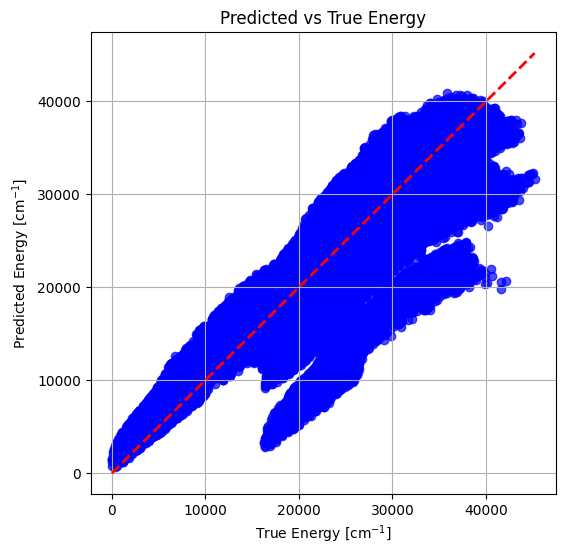

In [14]:
#Kernel Ridge Regression
ridge = Ridge(alpha=2.)
ridge.fit(X_train, y_train)

y_pred = ridge.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.4f}")
print(f"R² Score: {r2:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel(r"True Energy [cm$^{-1}$]")
plt.ylabel(r"Predicted Energy [cm$^{-1}$]")
plt.title("Predicted vs True Energy")
plt.grid(True)
plt.show()


Mean Squared Error (MSE): 707852.2420
Root Mean Squared Error (RMSE): 841.3396
R² Score: 0.9906


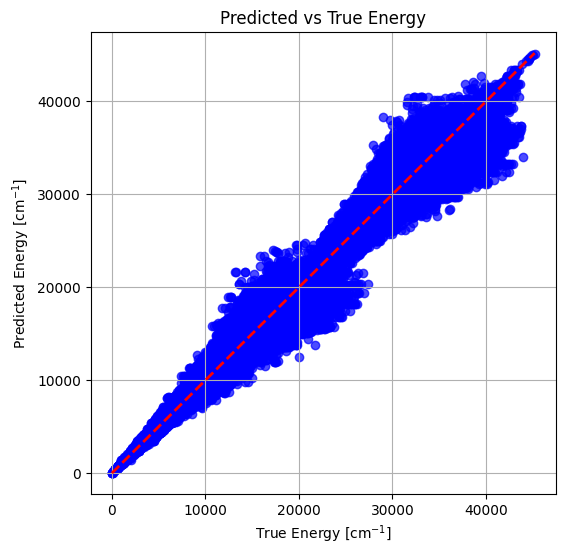

In [15]:
#Decision Tree
tree = DecisionTreeRegressor(max_depth=15)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.4f}")
print(f"R² Score: {r2:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel(r"True Energy [cm$^{-1}$]")
plt.ylabel(r"Predicted Energy [cm$^{-1}$]")
plt.title("Predicted vs True Energy")
plt.grid(True)
plt.show()


Mean Squared Error (MSE): 598816.1218
Root Mean Squared Error (RMSE): 773.8321
R² Score: 0.9920


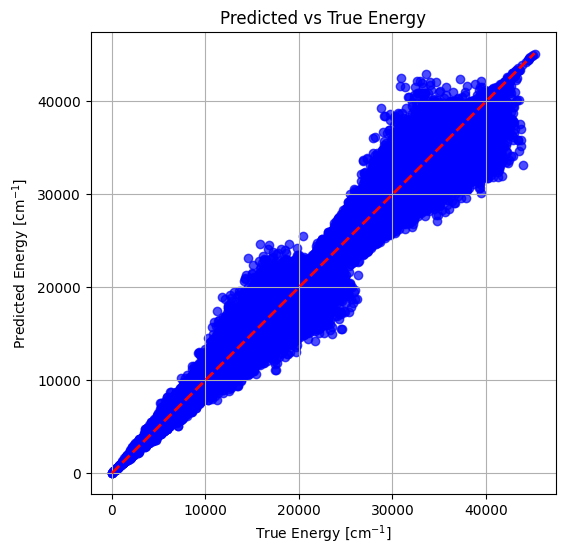

In [16]:
#Random Forest Regression
rf = RandomForestRegressor(n_estimators=10)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.4f}")
print(f"R² Score: {r2:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel(r"True Energy [cm$^{-1}$]")
plt.ylabel(r"Predicted Energy [cm$^{-1}$]")
plt.title("Predicted vs True Energy")
plt.grid(True)
plt.show()

Mean Squared Error (MSE): 700307.2834
Root Mean Squared Error (RMSE): 836.8436
R² Score: 0.9907


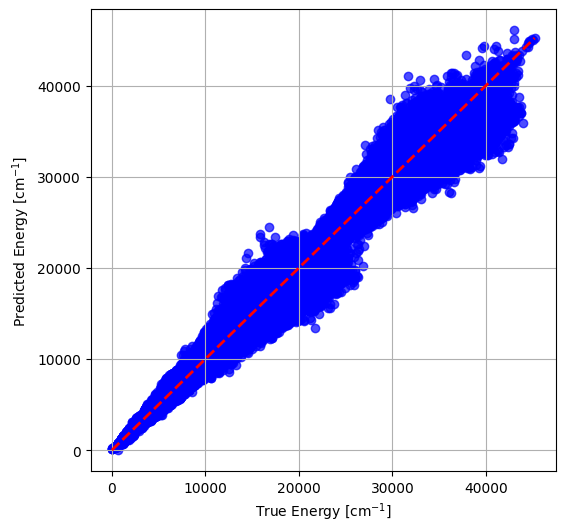

In [17]:
# Gradient Boosting  Regression

gbr = GradientBoostingRegressor(n_estimators=20, learning_rate=0.75, max_depth=10)
gbr.fit(X_train, y_train)


y_pred = gbr.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.4f}")
print(f"R² Score: {r2:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("True Energy")
plt.xlabel(r"True Energy [cm$^{-1}$]")
plt.ylabel(r"Predicted Energy [cm$^{-1}$]")
plt.grid(True)
plt.show()

As in the classification case, we will use the previously created small subset for the SVR and for a NN model.

In [18]:
# Define train and test sets for regression
X_train_small, X_test_small, y_train_small, y_test_small = train_test_split(X_small, y_reg_small, test_size=0.2)

Mean Squared Error (MSE): 573940.3039
Root Mean Squared Error (RMSE): 757.5885
R² Score: 0.9909


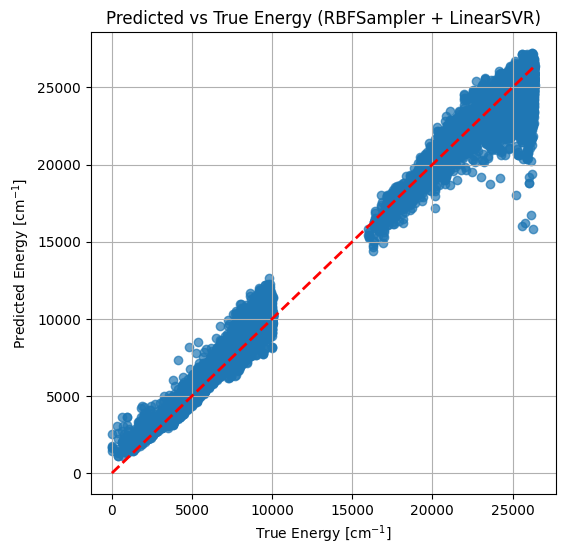

In [19]:
# scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_small)
X_test_scaled = scaler.transform(X_test_small)

# approximate RBF kernel
rbf_feature = RBFSampler(gamma=0.1, n_components=1000, random_state=42)
X_feat = rbf_feature.fit_transform(X_scaled)
X_test_feat = rbf_feature.transform(X_test_scaled)

# linear SVR using same C and epsilon
svr_lin = LinearSVR(C=100, epsilon=0.01, max_iter=2000, random_state=42)
svr_lin.fit(X_feat, y_train_small)


y_pred = svr_lin.predict(X_test_feat)
mse = mean_squared_error(y_test_small, y_pred)
r2 = r2_score(y_test_small, y_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.4f}")
print(f"R² Score: {r2:.4f}")



# plot
plt.figure(figsize=(6,6))
plt.scatter(y_test_small, y_pred, alpha=0.7)
plt.plot([y_test_small.min(), y_test_small.max()],
         [y_test_small.min(), y_test_small.max()], 'r--', linewidth=2)
plt.xlabel(r"True Energy [cm$^{-1}$]")
plt.ylabel(r"Predicted Energy [cm$^{-1}$]")
plt.title("Predicted vs True Energy (RBFSampler + LinearSVR)")
plt.grid(True)
plt.show()

Mean Squared Error (MSE): 13329435.6037
Root Mean Squared Error (RMSE): 3650.9500
R² Score: 0.7885


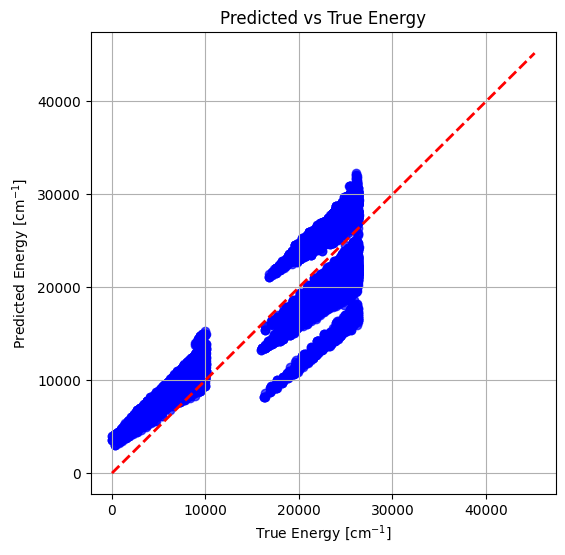

In [20]:
# Multi Layer Perceptron
mlp = MLPRegressor(hidden_layer_sizes=(128,64), activation='relu',
                   solver='adam', alpha=1e-4, learning_rate='adaptive',
                   max_iter=150, early_stopping=True, random_state=42)
mlp.fit(X_train_small, y_train_small)

y_pred = mlp.predict(X_test_small)

mse = mean_squared_error(y_test_small, y_pred)
r2 = r2_score(y_test_small, y_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.4f}")
print(f"R² Score: {r2:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(y_test_small, y_pred, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel(r"True Energy [cm$^{-1}$]")
plt.ylabel(r"Predicted Energy [cm$^{-1}$]")
plt.title("Predicted vs True Energy")
plt.grid(True)
plt.show()

In [21]:
import tensorflow as tf
from keras.callbacks import EarlyStopping
from scipy.stats import pearsonr


l1=512
l2=256
size=0.2
dropout=0.2
rate=0.0005
l2norm=0.0002
epoch=100


X_train, X_tmp, Y_train, Y_tmp = train_test_split(X_small, y_reg_small, test_size=0.2)#, random_state=42)
X_valid, X_test, Y_valid, Y_test = train_test_split(X_tmp, Y_tmp,  test_size=0.5)#, random_state=42)

# Normalize the input data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_valid_scaled = scaler.transform(X_valid)

# Build the model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(l1, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(l2norm)),
    tf.keras.layers.Dropout(dropout),
    tf.keras.layers.Dense(l2, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(l2norm)),
    tf.keras.layers.Dense(1,activation='relu')#,activation='softmax')  # Output layer for regression
])

# Compile the model with a specified learning rate and custom loss function
learning_rate = rate
adam_optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

model.compile(optimizer=adam_optimizer,
              loss='mean_squared_error')

# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# Train the model and pass sample weights
history=model.fit(X_train_scaled, Y_train, epochs=100, validation_data=(X_valid_scaled, Y_valid),callbacks=[early_stopping])

# Make predictions on the test set
predictions = model.predict(X_test_scaled)


Epoch 1/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - loss: 70697112.0000 - val_loss: 16478327.0000
Epoch 2/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - loss: 14412710.0000 - val_loss: 10109156.0000
Epoch 3/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 3239086.5000 - val_loss: 509309.9375
Epoch 4/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - loss: 630014.3750 - val_loss: 306936.4688
Epoch 5/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 548476.1875 - val_loss: 289010.2500
Epoch 6/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 532061.5000 - val_loss: 288370.1875
Epoch 7/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 519735.4062 - val_loss: 284898.4688
Epoch 8/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - loss: 515732.7188 - val_loss: 278717.6562
Epoch 9/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - loss: 504178.6250 - val_loss: 278937.5625
Epoch 10/100
3020/3020 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - loss: 488091.8438 - val_loss: 26

In [22]:
# Calculate overall MSE and MAE
overall_mse = mean_squared_error(Y_test, predictions)
overall_mae = mean_absolute_error(Y_test, predictions)

# Print overall results
print(f"Overall MSE: {overall_mse}")
print(f"Overall RMSE: {np.sqrt(overall_mse)}")
print(f"Overall MAE: {overall_mae}")

# Compute Pearson correlation between the true values and the predictions
correlation, p_value = pearsonr(Y_test, predictions.ravel())

# Print Pearson correlation
print(f"Pearson Correlation: {correlation}")
print(f"P-value: {p_value}")


Overall MSE: 149719.70238021284
Overall RMSE: 386.936302742729
Overall MAE: 282.0383278255268
Pearson Correlation: 0.9988143876676352
P-value: 0.0


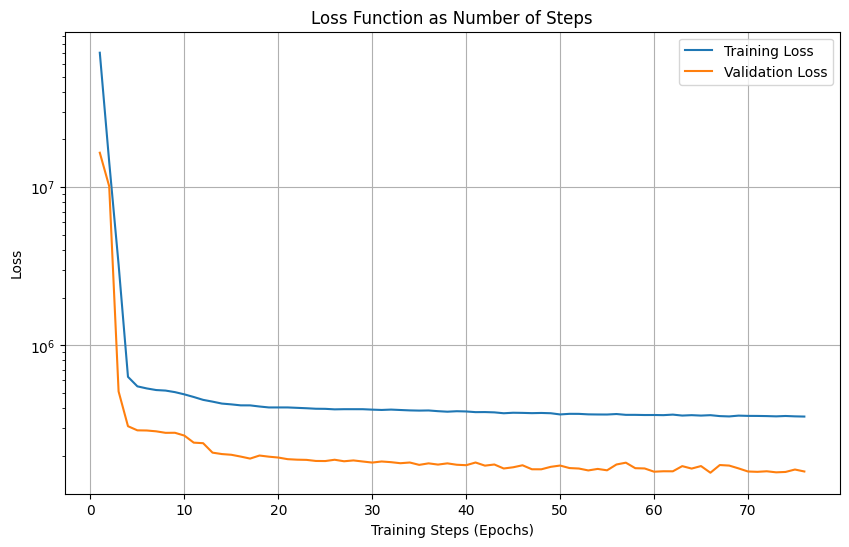

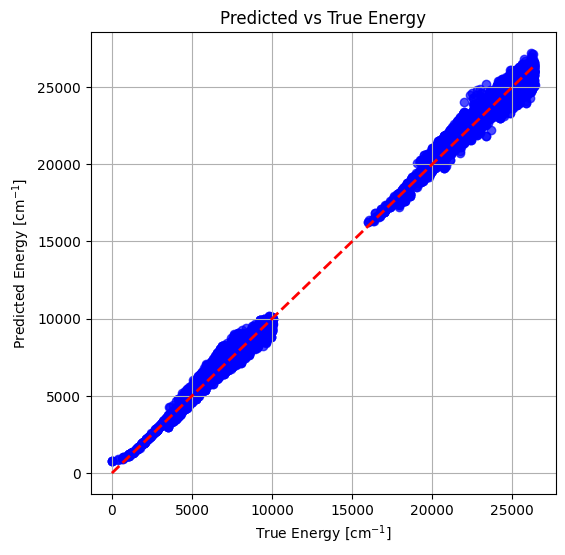

In [23]:
loss = history.history['loss']
val_loss = history.history['val_loss']
steps = range(1, len(loss) + 1)

# Plot the loss
plt.figure(figsize=(10, 6))
plt.yscale("log")

plt.plot(steps, loss, label='Training Loss')
plt.plot(steps, val_loss, label='Validation Loss')
plt.title('Loss Function as Number of Steps')
plt.xlabel('Training Steps (Epochs)')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(6,6))
plt.scatter(Y_test, predictions, alpha=0.7, color='blue')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', linewidth=2)
plt.xlabel(r"True Energy [cm$^{-1}$]")
plt.ylabel(r"Predicted Energy [cm$^{-1}$]")
plt.title("Predicted vs True Energy")
plt.grid(True)
plt.show()

__Questions__
1. What is the best Regression predictors for the entire dataset? Observing the plots, can you understand why is it the case? (__Hint:__ plot the energies as function of the electronic states)
2. Why does the custom Neural Network works better than the MLP?

__Exercise 3__

We will see a bit of clustering and dimensionality reduction to see how we can play with  reducing the size of the observed problem. First of all we will try to reduce the dimensionality of our problem, try to plot the results of it, and then try to perform some prediction with the reduced model.

Explained variance ratio: [0.34343163 0.15205221]


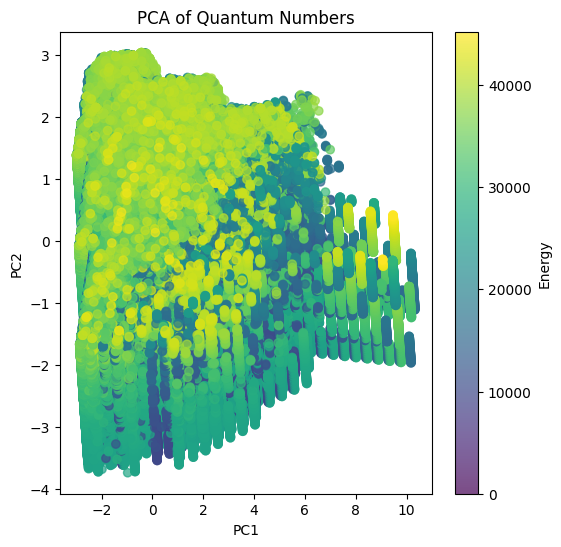

In [24]:
#PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)  # reduce to 2 dimensions for visualization
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)

plt.figure(figsize=(6,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y_reg, cmap='viridis', alpha=0.7)
plt.colorbar(label="Energy")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Quantum Numbers")
plt.show()



In [25]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

# Compute feature contributions (squared loadings normalized per component)
contributions = loadings**2
contributions = contributions / contributions.sum(axis=0)

# Put into a DataFrame for readability
contrib_df = pd.DataFrame(contributions,
                          index=features,
                          columns=[f"PC{i+1}" for i in range(pca.n_components_)])

print(contrib_df)

                PC1       PC2
J          0.008672  0.294343
L          0.276335  0.001113
v1         0.035486  0.278374
v2         0.146499  0.036563
l2         0.278161  0.000953
v3         0.042918  0.183500
omega      0.191872  0.069673
fidx_num   0.016739  0.135231
label_num  0.003319  0.000250


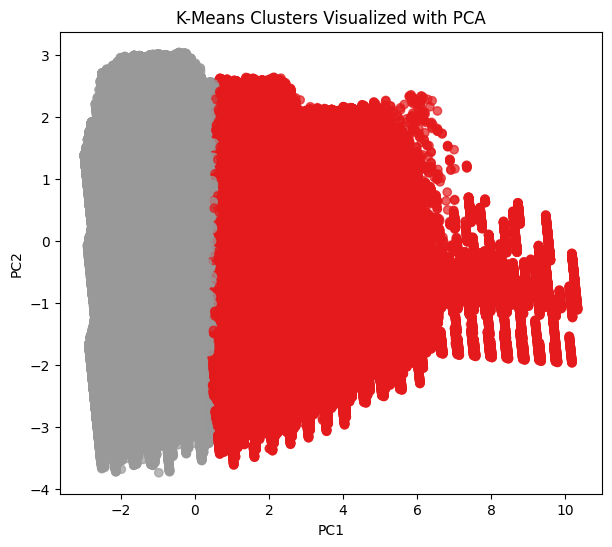

In [26]:
#K-Means on the PCA
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(X_pca)

# Plot clusters
plt.figure(figsize=(7,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap='Set1', alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clusters Visualized with PCA")
plt.show()

Explained variance ratio: [0.3753225  0.15074084 0.12846163 0.11602276 0.10754114 0.08356931]
RMSE: 492.78527713653864
R2: 0.9961710785369556


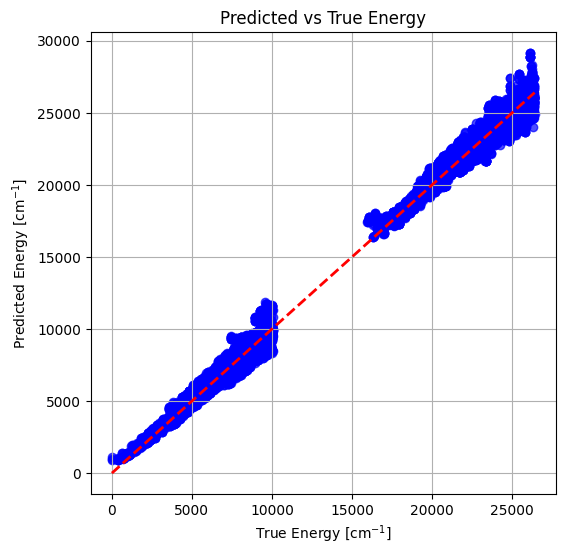

In [27]:
X_scaled = scaler.fit_transform(X_small)

pca = PCA(n_components=6)  # reduce to N dimension
X_pca = pca.fit_transform(X_scaled)
print("Explained variance ratio:", pca.explained_variance_ratio_)

X_train, X_test, y_train, y_test = train_test_split(X_pca, y_reg_small, test_size=0.2, random_state=42)

# MLP regressor using PCA descriptor
mlp = MLPRegressor(hidden_layer_sizes=(128,64), activation='relu',
                   solver='adam', alpha=1e-4, learning_rate='adaptive',
                   max_iter=1000, early_stopping=True, random_state=42)
mlp.fit(X_train, y_train)

y_pred = mlp.predict(X_test)
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel(r"True Energy [cm$^{-1}$]")
plt.ylabel(r"Predicted Energy [cm$^{-1}$]")
plt.title("Predicted vs True Energy")
plt.grid(True)
plt.show()

Classification Accuracy: 0.9980960264900662


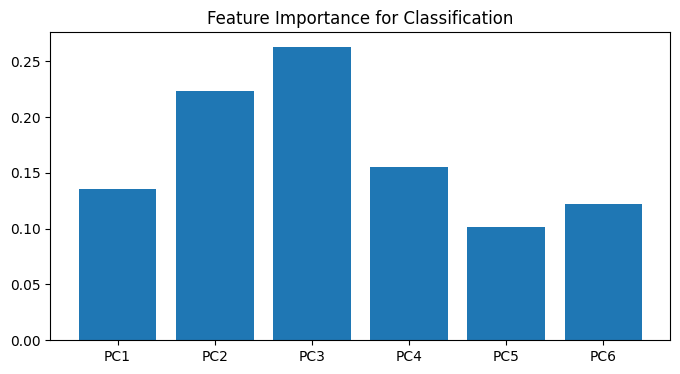

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X_pca, y_class_small, test_size=0.2)

#Random Forest Classification
clf = RandomForestClassifier(n_estimators=20)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Classification Accuracy:", accuracy_score(y_test, y_pred))


k = X_pca.shape[1]   # number of PCA components used
pca_features = [f"PC{i+1}" for i in range(k)]

# Feature importance plot
importances = clf.feature_importances_
plt.figure(figsize=(8,4))
plt.bar(pca_features, importances)
plt.title("Feature Importance for Classification")
plt.show()

__Questions__
1. How many PCA components are required to describe the 85% of properties of your system?
2. How does the MLP model when using a PCA model that encodes this amount of informatiom?
3. How these models perform in respect to the ones where you are using all the features?